# Computing Hamming Weight

In this tutorial, we will go over Workbench Algorithms Qubricks used to compute the Hamming weight of a quantum register.

The Hamming weight of a bit string is defined as the number of ones in that bit string. For example, the bit string `01101` has a Hamming weight of $3$. Some quantum algorithms, such as Hamming weight phasing, need to compute the Hamming weight of a quantum register coherently, so that we can pass in states in superposition and compute the associated Hamming weights in superposition.

Therefore, we need a quantum circuit that implements the following operation:

$$
\renewcommand{\ket}[1]{|#1\rangle}
    U_{\text{Hamming Weight}} \ket{\psi}\ket{0} = \ket{\psi}\ket{\text{Hamming Weight}(\psi)} 
$$

Currently, Workbench Algorithms offers three different Qubricks that compute the Hamming weight of a quantum register: [`ComputeHammingWeightNaive`](https://docs.construct.psiquantum.com/psiqdk-algorithms/autoapi/psiqdk/algorithms/index.html#psiqdk.algorithms.ComputeHammingWeightNaive), [`ComputeHammingWeightGroupOfThrees`](https://docs.construct.psiquantum.com/psiqdk-algorithms/autoapi/psiqdk/algorithms/index.html#psiqdk.algorithms.ComputeHammingWeightGroupOfThrees), and [`ComputeHammingWeightBinaryRecursion`](https://docs.construct.psiquantum.com/psiqdk-algorithms/autoapi/psiqdk/algorithms/index.html#psiqdk.algorithms.ComputeHammingWeightBinaryRecursion).

While we won't go into detail on how each of these implementations work, we will show you how to use them and do some quick resource estimates to show the tradeoffs between them. We'll stick to the default adder Qubrick, `GidneyAdd`, but you can supply whichever adder you'd like and check if that makes a difference in your resource counts!

In [1]:
from itertools import product
import matplotlib.pyplot as plt
from psiqdk.workbench import QPU, Qubits, Qubrick
from psiqdk.workbench.filter_presets import NO_SIM_DEFAULT
from psiqdk.workbench.qre import resource_estimator
from psiqdk.algorithms import ComputeHammingWeightNaive, ComputeHammingWeightGroupOfThrees, ComputeHammingWeightBinaryRecursion

## Naive algorithm

First and foremost, let's see how to use the `ComputeHammingWeightNaive` Qubrick. The algorithm for this circuit is straightforward: allocate an empty register `hamming_weight` and then serially add the value of the qubits in the `input` register to it. Therefore, for each qubit in the `input` register, you see an adder block in the circuit, with that qubit as the source and `hamming_weight` as the sum.

The following code snippet demonstrates the use of this Qubrick and the Hamming weights calculated for all input bit strings.

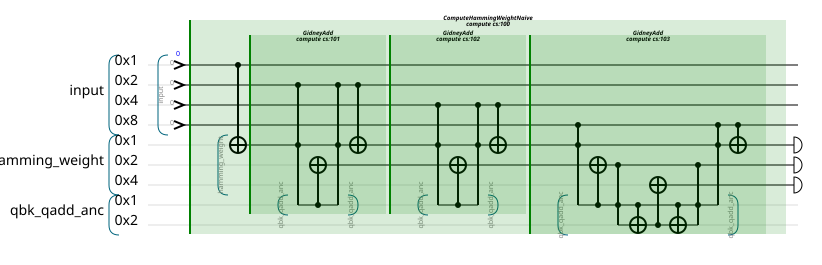

| Input | HW (quantum) | HW (classical) | Updated input |
|   0   |      0       |       0        |       0       |
|   1   |      1       |       1        |       1       |
|   2   |      1       |       1        |       2       |
|   3   |      2       |       2        |       3       |
|   4   |      1       |       1        |       4       |
|   5   |      2       |       2        |       5       |
|   6   |      2       |       2        |       6       |
|   7   |      3       |       3        |       7       |
|   8   |      1       |       1        |       8       |
|   9   |      2       |       2        |       9       |
|  10   |      2       |       2        |      10       |
|  11   |      3       |       3        |      11       |
|  12   |      2       |       2        |      12       |
|  13   |      3       |       3        |      13       |
|  14   |      3       |       3        |      14       |
|  15   |      4       |       4        |      15       |


In [2]:
def run_hamming_weight_example(hw_class: type[Qubrick], num_qubits: int):
    input_size = 4
    for value in range(1 << input_size):
        qpu = QPU(num_qubits=num_qubits)
        input = Qubits(input_size, "input", qpu)
        input.write(value)

        hw_qbk = hw_class()
        hw_qbk.compute(input)
        
        hw_reg = hw_qbk.get_result_qreg()
        hw_res = hw_reg.read()

        if value == 0:
            qpu.draw(show_qubricks=True)
            print("| Input | HW (quantum) | HW (classical) | Updated input |")
        print(f"| {value:^5} | {hw_res:^12} | {value.bit_count():^14} | {input.read():^13} |")

run_hamming_weight_example(ComputeHammingWeightNaive, 9)

Indeed, you can see the printed table of correct Hamming weights of all basis states of length $4$.

## Group-of-threes algorithm

The `ComputeHammingWeightGroupOfThrees` Qubrick is a much more gate-efficient method to compute the Hamming weight! The catch is that it uses a linear number of auxiliary qubits and is much more costly when controlled.

This Qubrick computes the Hamming weight by taking size-3 subsets of the target register and adding them up, then taking the results and adding them up with remaining subsets, and so on, until there are no remaining qubits in the target register.

The following example demonstrates the use of this Qubrick. Note that, unlike in the previous case, the resulting register of the Qubrick is composed of a combination of freshly allocated auxiliary qubits and qubits that are part of the input. This Qubrick also modifies the input register! If you want to have both the original inputs and the computed Hamming weights, you'll need to copy the results to a fresh register and then uncompute the Qubrick to restore the original inputs.

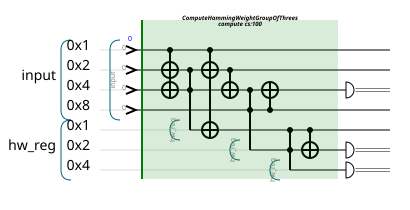

| Input | HW (quantum) | HW (classical) | Updated input |
|   0   |      0       |       0        |       0       |
|   1   |      1       |       1        |       5       |
|   2   |      1       |       1        |       6       |
|   3   |      2       |       2        |       3       |
|   4   |      1       |       1        |       4       |
|   5   |      2       |       2        |       1       |
|   6   |      2       |       2        |       2       |
|   7   |      3       |       3        |       7       |
|   8   |      1       |       1        |      12       |
|   9   |      2       |       2        |       9       |
|  10   |      2       |       2        |      10       |
|  11   |      3       |       3        |      15       |
|  12   |      2       |       2        |       8       |
|  13   |      3       |       3        |      13       |
|  14   |      3       |       3        |      14       |
|  15   |      4       |       4        |      11       |


In [3]:
run_hamming_weight_example(ComputeHammingWeightGroupOfThrees, 7)

## Binary recursion

`ComputeHammingWeightBinaryRecursion` Qubrick is another nice implementation that uses fewer auxiliary qubits (but still a linear number in the size of the input register) and around the same number of Toffoli gates.

This method is similar to the one above in spirit (in terms of using subsets of target register qubits), but it uses parallel implementations of half-adders, then adds up the results using larger adders going through a binary tree structure.

Same as the previous Qubrick, it modifies its input register and reuses part of it as part of the result register.

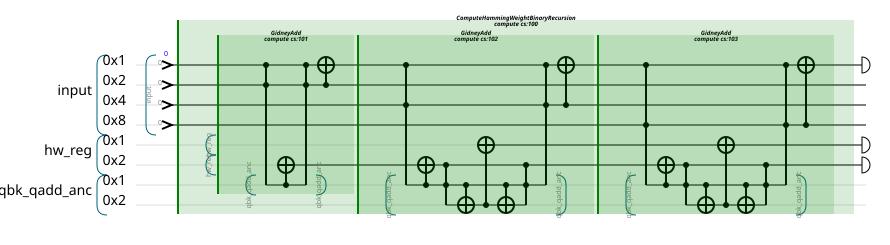

| Input | HW (quantum) | HW (classical) | Updated input |
|   0   |      0       |       0        |       0       |
|   1   |      1       |       1        |       1       |
|   2   |      1       |       1        |       3       |
|   3   |      2       |       2        |       2       |
|   4   |      1       |       1        |       5       |
|   5   |      2       |       2        |       4       |
|   6   |      2       |       2        |       6       |
|   7   |      3       |       3        |       7       |
|   8   |      1       |       1        |       9       |
|   9   |      2       |       2        |       8       |
|  10   |      2       |       2        |      10       |
|  11   |      3       |       3        |      11       |
|  12   |      2       |       2        |      12       |
|  13   |      3       |       3        |      13       |
|  14   |      3       |       3        |      15       |
|  15   |      4       |       4        |      14       |


In [4]:
run_hamming_weight_example(ComputeHammingWeightBinaryRecursion, 8)

## Resource estimation

Now, let's compare some of the resource estimates of these three implementations.

For a range of system sizes, we will plot the number of Toffoli gates and the number of auxiliary qubits each method uses, for both the uncontrolled and controlled versions of these routines.

In [5]:
input_sizes = range(10, 100, 5)
qubricks = [ComputeHammingWeightNaive, ComputeHammingWeightGroupOfThrees, ComputeHammingWeightBinaryRecursion]

def fetch_hamming_weight_metrics(input_size: int, hw_class: type[Qubrick], controlled: int):
    qpu = QPU(num_qubits=3 * input_size, filters=NO_SIM_DEFAULT)
    input = Qubits(input_size, "input", qpu)
    hw_qbk = hw_class()
    if controlled:
        ctrl = Qubits(1, "ctrl", qpu)
        hw_qbk.compute(input, ctrl)
    else:
        hw_qbk.compute(input)

    resources = resource_estimator(qpu).resources()
    n_aux = int(resources["qubit_highwater"]) - input_size - (1 if controlled else 0)
    # Left Gidney elbows are equivalent to Toffoli gates here
    n_toffs = int(resources["toffs"]) + int(resources["gidney_lelbows"])
    return n_toffs, n_aux

n_toffoli = [[[0] * len(input_sizes) for _ in range(2)] for _ in range(3)]
n_aux = [[[0] * len(input_sizes) for _ in range(2)] for _ in range(3)]
for qubrick_ind, controlled, input_ind in product(range(3), [0, 1], range(len(input_sizes))):
    toffoli, aux = fetch_hamming_weight_metrics(input_sizes[input_ind], qubricks[qubrick_ind], controlled)
    n_toffoli[qubrick_ind][controlled][input_ind] = toffoli
    n_aux[qubrick_ind][controlled][input_ind] = aux

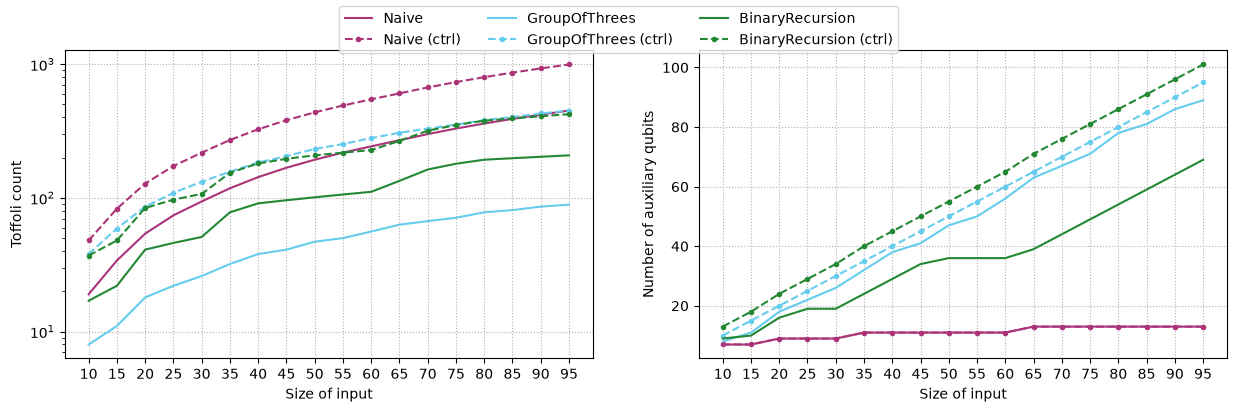

In [6]:
colors = ["#AB3377", "#66CCEE", "#228833"]
qubrick_names = ["Naive", "GroupOfThrees", "BinaryRecursion"]

def do_resource_subplot(ax, data):
    for qubrick_ind, controlled in product(range(3), range(2)):
        ax.plot(input_sizes, data[qubrick_ind][controlled], 
                color=colors[qubrick_ind], 
                label=qubrick_names[qubrick_ind] + (" (ctrl)" if controlled else ""),
                linestyle="--" if controlled else "-",
                marker="." if controlled else "")
    ax.set(xticks=input_sizes)
    ax.grid(linestyle=":")
    ax.set(xlabel="Size of input")

fig, axes = plt.subplots(nrows=1, ncols=2 , figsize=(15, 4))
do_resource_subplot(axes[0], n_toffoli)
axes[0].set(yscale="log")
axes[0].set(ylabel="Toffoli count")
do_resource_subplot(axes[1], n_aux)
axes[1].set(ylabel="Number of auxiliary qubits")

fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=3);

You can see that the naive algorithm uses the fewest auxiliary qubits and the most Toffoli gates. The other two algorithms trade off Toffoli gates and auxiliary qubits depending on whether the routine is controlled or not.

## Summary

In this tutorial, we walked through computing the Hamming weight of a quantum register and the Qubricks that Workbench Algorithms provides for this:

* `ComputeHammingWeightNaive` is the most straightforward algorithm, requiring the most Toffoli gates and the fewest additional qubits.
* `ComputeHammingWeightGroupOfThrees` and `ComputeHammingWeightBinaryRecursion` rely on more sophisticated algorithms, requiring fewer Toffoli gates and more auxiliary qubits. They also modify the input register as part of the computation, which is something you need to keep in mind when using them.